# ` Intelligent E-Commerce Customer Analytics Platform `

## Objectives
- Answer business questions such as:

    - 1. Why is this customer likely to purchase again?
    - 2. Which features contribute most to Customer Lifetime Value?
    - 3. Why did the model make this prediction?

# Step 1 – Install SHAP

In [1]:
!pip3 install shap

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


# Step 2 – Import Libraries

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import shap
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split

shap.initjs()
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer


import warnings
warnings.filterwarnings("ignore")



# Step 3 – Prepare the Modeling Dataset

In [3]:
from pathlib import Path
cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd if (cwd / "data" / "processed").is_dir() else cwd.parent
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "customer_analytics_featured.csv"
if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Cannot locate dataset: {DATA_PATH}")
customer_df = pd.read_csv(DATA_PATH)
customer_df.head() 

# Convert purchase Date
customer_df["order_purchase_timestamp"] = pd.to_datetime(
    customer_df["order_purchase_timestamp"]
)

# Sort Customer Purchase
customer_df = customer_df.sort_values(
    ["customer_unique_id", "order_purchase_timestamp"]
)

# Find Next Purchase Date
customer_df["Next_Purchase_Date"] = (
    customer_df.groupby("customer_unique_id")["order_purchase_timestamp"]
               .shift(-1)
)

# Calculate Days Until Next Purchase
customer_df["Days_To_Next_Purchase"] = (
    customer_df["Next_Purchase_Date"]
    - customer_df["order_purchase_timestamp"]
).dt.days

# Create Target Variable
customer_df["Repeat_Purchase"] = np.where(
    customer_df["Days_To_Next_Purchase"] <= 90,
    1,
    0
)

# Handle Last Purchase
    # Customers with no future purchase have NaN for Days_To_Next_Purchase.

customer_df["Repeat_Purchase"] = (
    customer_df["Repeat_Purchase"]
    .fillna(0)
    .astype(int)
)

# Target Distribution
customer_df["Repeat_Purchase"].value_counts()




# Remove Leakage Columns

drop_columns = [

    # IDs
    "customer_id",
    "customer_unique_id",
    "order_id",
    "review_id",
    "product_id",
    "seller_id",

    # Free text
    "review_comment_title",
    "review_comment_message",

    # Raw timestamps
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_customer_date",
    "order_delivered_carrier_date",
    "order_estimated_delivery_date",
    "shipping_limit_date",
    "review_creation_date",
    "review_answer_timestamp",

    # Leakage
    "Next_Purchase_Date",
    "Days_To_Next_Purchase",
    "Repeat_Purchase"
]

X = customer_df.drop(columns=drop_columns, errors="ignore")
y = customer_df["Repeat_Purchase"]

# Step 4 – Explain the Repeat Purchase Prediction Model (LightGBM)

In [4]:
# Load Saved Model & Preprocessor
loaded_model = joblib.load(PROJECT_ROOT / "artifacts" / "lightgbm_repeat_purchase_model.pkl")
preprocessor = joblib.load(PROJECT_ROOT / "artifacts" / "preprocessor.pkl")
model = loaded_model

# Identify Feature Types
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()
print("Numerical Features :", len(numeric_features))
print("Categorical Features :", len(categorical_features))

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
print("Training Shape :", X_train.shape)
print("Testing Shape  :", X_test.shape)

# Transform the Data
X_train_processed = preprocessor.transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed Training Shape :", X_train_processed.shape)
print("Processed Testing Shape  :", X_test_processed.shape)

Numerical Features : 25
Categorical Features : 12
Training Shape : (95314, 37)
Testing Shape  : (23829, 37)
Processed Training Shape : (95314, 8735)
Processed Testing Shape  : (23829, 8735)


In [5]:
# Generate and save SHAP artifacts for the saved LightGBM model.
# Run the earlier data-preparation and train/test-split cells first (X_test required).
import joblib
import numpy as np
import shap
from pathlib import Path
from scipy import sparse

# Resolve paths whether Jupyter starts in the project root or notebooks/.
working_dir = Path.cwd().resolve()
if (working_dir / "artifacts").is_dir():
    project_root = working_dir
elif (working_dir.parent / "artifacts").is_dir():
    project_root = working_dir.parent
else:
    raise FileNotFoundError(
        "Cannot locate project artifacts/ directory. Open the notebook from "
        "the project root or notebooks/ directory."
    )
artifacts_path = project_root / "artifacts"

model_path = artifacts_path / "lightgbm_repeat_purchase_model.pkl"
preprocessor_path = artifacts_path / "preprocessor.pkl"
for required_path in (model_path, preprocessor_path):
    if not required_path.is_file():
        raise FileNotFoundError(f"Required trained artifact missing: {required_path}")

loaded_model = joblib.load(model_path)
preprocessor = joblib.load(preprocessor_path)

# Use exactly the saved preprocessing pipeline and transformed feature order.
# Ensure raw columns match the fitted preprocessor's expected schema.
if hasattr(preprocessor, "feature_names_in_"):
    required_columns = list(preprocessor.feature_names_in_)
    missing_columns = [c for c in required_columns if c not in X_test.columns]
    if missing_columns:
        raise ValueError(f"Missing saved-preprocessor inputs: {missing_columns[:10]}")
    X_for_shap = X_test.loc[:, required_columns]
else:
    X_for_shap = X_test
X_test_processed = preprocessor.transform(X_for_shap)
feature_names = list(preprocessor.get_feature_names_out())

sample_count = min(500, X_test_processed.shape[0])
if sample_count == 0:
    raise ValueError("X_test is empty; cannot generate SHAP explanations.")
X_sample = X_test_processed[:sample_count]
if sparse.issparse(X_sample):
    X_sample = X_sample.toarray()
else:
    X_sample = np.asarray(X_sample)

if X_sample.shape[1] != len(feature_names):
    raise ValueError("Transformed feature count does not match feature names.")
if hasattr(loaded_model, "n_features_in_") and X_sample.shape[1] != loaded_model.n_features_in_:
    raise ValueError("Saved LightGBM model expects a different feature count.")

explainer = shap.Explainer(loaded_model)
shap_values_sample = explainer(X_sample)
shap_values_sample.feature_names = feature_names
if shap_values_sample.values.shape[0] != sample_count:
    raise ValueError("SHAP row count differs from the sampled records.")

# Persist the exact Explanation object used by the notebook's plots.
joblib.dump(shap_values_sample, artifacts_path / "shap_values_sample.pkl")
joblib.dump(feature_names, artifacts_path / "shap_feature_names.pkl")
np.save(artifacts_path / "shap_sample.npy", X_sample)

print("SHAP explanations:", shap_values_sample.values.shape)
print("Saved artifacts in:", artifacts_path)
for filename in ("shap_values_sample.pkl", "shap_feature_names.pkl", "shap_sample.npy"):
    path = artifacts_path / filename
    print(f"  {filename}: {path.exists()} ({path.stat().st_size:,} bytes)")


SHAP explanations: (500, 8735)
Saved artifacts in: C:\Users\RAaM\OneDrive\Desktop\E-Commerce Customer Analytics\artifacts
  shap_values_sample.pkl: True (140,072,728 bytes)
  shap_feature_names.pkl: True (303,282 bytes)
  shap_sample.npy: True (34,940,128 bytes)


# Step 5 – Create SHAP Explainer

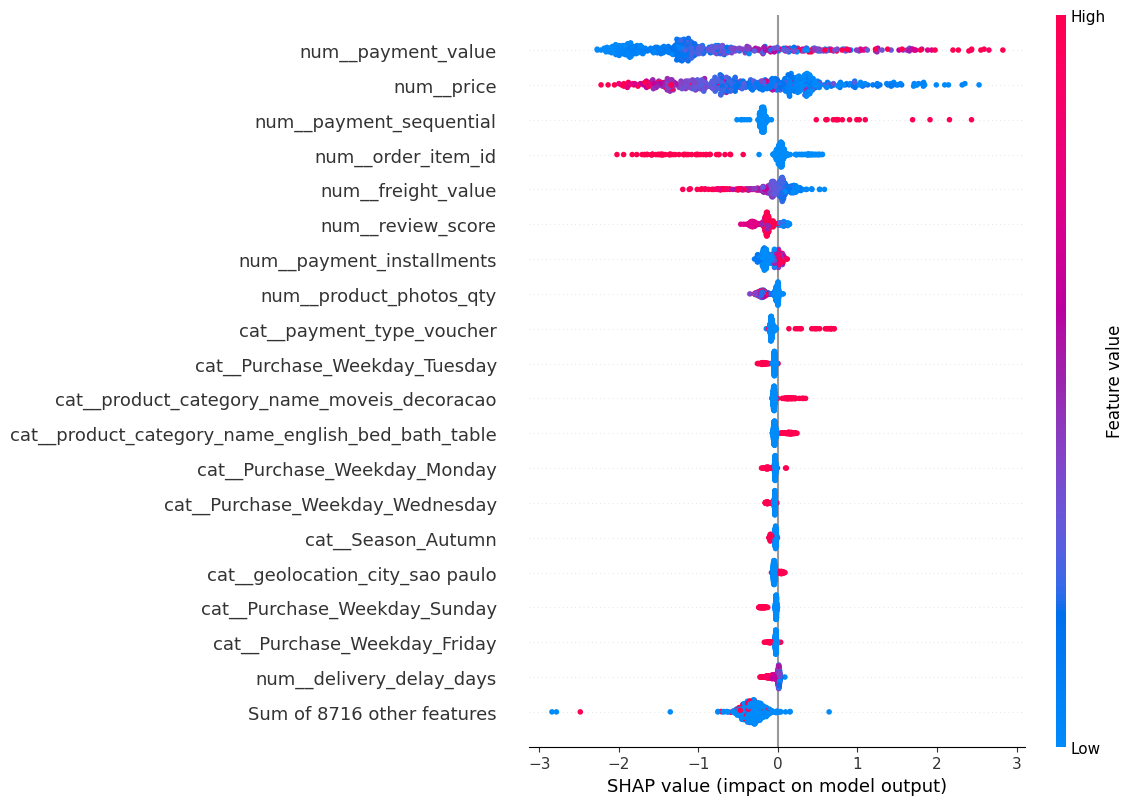

In [6]:
# Reuse the SHAP Explanation generated in the previous cell.
# Avoid recalculating a second 500 x 8,735 explanation.
shap.plots.beeswarm(shap_values_sample, max_display=20)


# How to interpret the global plot

- The plotted feature rankings describe the legacy LightGBM model only.
- Large mean absolute SHAP values indicate greater average influence on the model output, not causation.
- Red and blue dots indicate higher and lower feature values when the saved sample data is available.
- SHAP output units depend on the explainer and model output (often raw score/log-odds), not necessarily probability.
- The feature names include payment value, price, and order-item fields. Some may reflect information unavailable at a genuine pre-purchase prediction cutoff; assess temporal leakage before treating this as a prospective forecast.
- A new explanation pipeline must be built separately for the v3 Logistic Regression model.

# Step 6 – SHAP Waterfall Plot

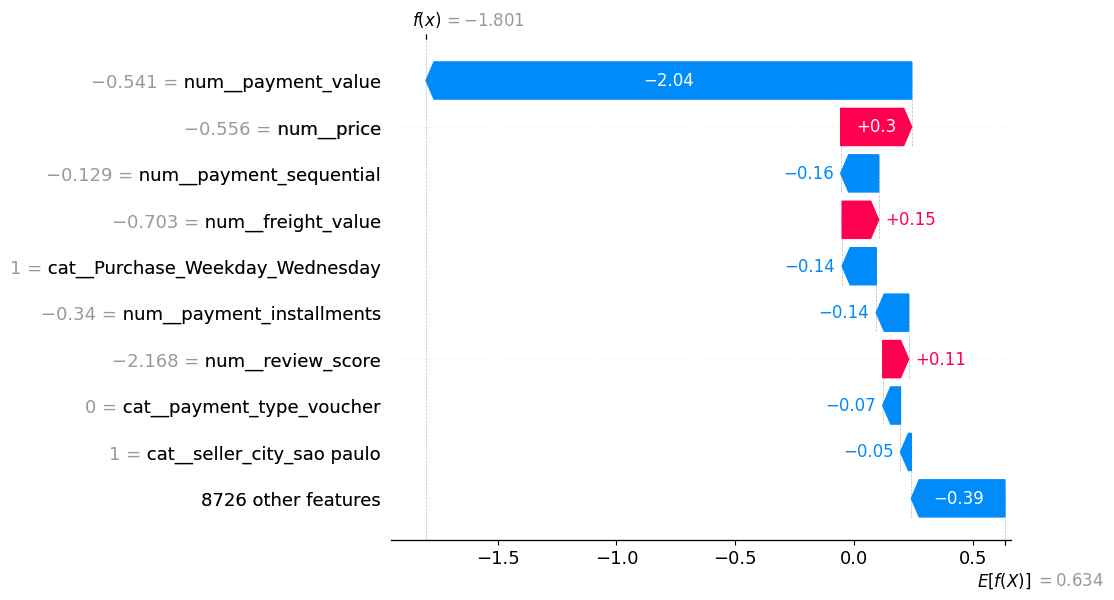

In [7]:
customer_index = 0
shap.plots.waterfall(shap_values_sample[customer_index])

- It answers:
    - Why is this specific customer predicted to purchase again?

- The waterfall plot shows which features push the prediction higher or lower relative to the baseline

# Step 7 – SHAP Force Plot

In [8]:
shap.plots.force(shap_values_sample[customer_index])

## Interpretation

    - The SHAP Force Plot explains the prediction for an individual customer. 
    - The model begins with the average prediction (base value) and adjusts it based on the customer's feature values. 
    - Blue features decrease the probability of repeat purchase, while red features increase it